# Linear Regression

## Import Dependencies

In [4]:
import torch
import torch.nn as nn
import numpy as np
from sklearn import datasets
import matplotlib.pyplot as plt

## Prepare Data

In [9]:
X_numpy, y_numpy = datasets.make_regression(n_samples=100, n_features=1, noise=20, random_state=1)

X = torch.from_numpy(X_numpy.astype(np.float32))
y = torch.from_numpy(y_numpy.astype(np.float32))
y = y.view(y.shape[0], 1) # convert to column vector

n_samples, n_features = X.shape

## Define the Model

In [10]:
input_size = n_features
output_size = 1

model = nn.Linear(input_size, output_size)

## Define Loss and Optimizer

In [11]:
learning_rate = 0.01

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

## Training Loop

epoch: 10, loss: 332.56756591796875
epoch: 20, loss: 332.56756591796875
epoch: 30, loss: 332.56756591796875
epoch: 40, loss: 332.56756591796875
epoch: 50, loss: 332.56756591796875
epoch: 60, loss: 332.56756591796875
epoch: 70, loss: 332.56756591796875
epoch: 80, loss: 332.56756591796875
epoch: 90, loss: 332.56756591796875
epoch: 100, loss: 332.56756591796875


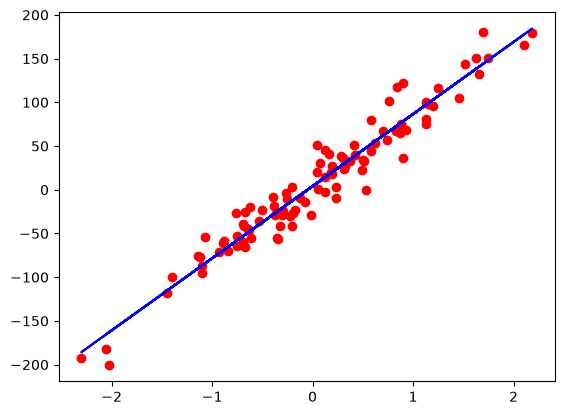

In [14]:
num_epochs = 100

for epoch in range(num_epochs):
    # forward pass & loss
    y_pred = model(X)
    loss = criterion(y_pred, y)
    
    # backward pass
    loss.backward()

    # update parameters
    optimizer.step()

    # empty gradients
    optimizer.zero_grad()

    if (epoch + 1) % 10 == 0:
        print(f"epoch: {epoch+1}, loss: {loss.item()}")

# MSE plot
prediction = model(X).detach().numpy()
plt.figure()
plt.plot(X_numpy, y_numpy, 'ro')
plt.plot(X_numpy, prediction, 'b')
plt.show()